# Lab 03 Homework

## 1. Data reading

Let's first see if every file is in the right place

In [2]:
from pathlib import Path

import polars as pl

DATA_DIR = Path("data")
monthly_files = [DATA_DIR / f"{month}.parquet" for month in range(1, 13)]
missing_files = [path for path in monthly_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Missing monthly Parquet files: "
        + ", ".join(str(path) for path in missing_files)
    )

zone_file = DATA_DIR / "taxi_zone_lookup.csv"
if not zone_file.is_file():
    raise FileNotFoundError(f"Missing taxi zone lookup file: {zone_file}")

Load the 2024 monthly taxi trip files and the taxi zone lookup as lazy Polars queries. Keep rides that start during 2024 and end no later than January 1, 2025

In [ ]:


rides_lf = pl.concat(
    [
        pl.scan_parquet(path).with_columns(
            pl.col("tpep_pickup_datetime").cast(pl.Datetime("ns")),
            pl.col("tpep_dropoff_datetime").cast(pl.Datetime("ns")),
        )
        for path in monthly_files
    ],
    how="vertical_relaxed",
)

pickup = pl.col("tpep_pickup_datetime")
dropoff = pl.col("tpep_dropoff_datetime")
rides_lf = (
    rides_lf
    .filter(
        (pickup >= pl.datetime(2024, 1, 1))
        & (pickup < pl.datetime(2025, 1, 1))
        & (dropoff <= pl.datetime(2025, 1, 1))
    )
)

zones_lf = (
    pl.scan_csv(zone_file)
)

Both objects are lazy. Let's their schemas and collect only a small preview

In [3]:
from IPython.display import display

print(rides_lf.collect_schema())
print(zones_lf.collect_schema())
display(rides_lf.head().collect())
display(zones_lf.head().collect())

Schema({'VendorID': Int16, 'tpep_pickup_datetime': Datetime(time_unit='ns', time_zone=None), 'tpep_dropoff_datetime': Datetime(time_unit='ns', time_zone=None), 'passenger_count': Int16, 'trip_distance': Float64, 'RatecodeID': Int16, 'store_and_fwd_flag': Categorical(ordering='physical'), 'PULocationID': Int16, 'DOLocationID': Int16, 'payment_type': Int16, 'fare_amount': Float64, 'extra': Float64, 'mta_tax': Float64, 'tip_amount': Float64, 'tolls_amount': Float64, 'improvement_surcharge': Float64, 'total_amount': Float64, 'congestion_surcharge': Float64, 'Airport_fee': Float64})
Schema({'LocationID': Int16, 'Borough': Categorical(ordering='physical'), 'Zone': Categorical(ordering='physical'), 'service_zone': Categorical(ordering='physical')})


VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
i16,datetime[ns],datetime[ns],i16,f64,i16,cat,i16,i16,i16,f64,f64,f64,f64,f64,f64,f64,f64,f64
2,2024-01-01 00:57:55,2024-01-01 01:17:43,1,1.72,1,"""N""",186,79,2,17.7,1.0,0.5,0.0,0.0,1.0,22.7,2.5,0.0
1,2024-01-01 00:03:00,2024-01-01 00:09:36,1,1.8,1,"""N""",140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
1,2024-01-01 00:17:06,2024-01-01 00:35:01,1,4.7,1,"""N""",236,79,1,23.3,3.5,0.5,3.0,0.0,1.0,31.3,2.5,0.0
1,2024-01-01 00:36:38,2024-01-01 00:44:56,1,1.4,1,"""N""",79,211,1,10.0,3.5,0.5,2.0,0.0,1.0,17.0,2.5,0.0
1,2024-01-01 00:46:51,2024-01-01 00:52:57,1,0.8,1,"""N""",211,148,1,7.9,3.5,0.5,3.2,0.0,1.0,16.1,2.5,0.0


LocationID,Borough,Zone,service_zone
i16,cat,cat,cat
1,"""EWR""","""Newark Airport""","""EWR"""
2,"""Queens""","""Jamaica Bay""","""Boro Zone"""
3,"""Bronx""","""Allerton/Pelham Gardens""","""Boro Zone"""
4,"""Manhattan""","""Alphabet City""","""Yellow Zone"""
5,"""Staten Island""","""Arden Heights""","""Boro Zone"""


## 2. Data cleaning and filtering

Clean the lazy trip query. Rate codes 1-6 and vendor IDs 1-2 are the recognized values, rate code 99 is the dictionary's null value, so it is excluded

In [4]:
money_columns = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]
valid_vendor_ids = [1, 2]
valid_ratecode_ids = [1, 2, 3, 4, 5, 6]

trip_duration = (
    pl.col("tpep_dropoff_datetime")
    - pl.col("tpep_pickup_datetime")
)
over_1000 = pl.any_horizontal(
    *[
        (pl.col(column).abs() > 1000).fill_null(False)
        for column in money_columns
    ]
)

rides_lf = (
    rides_lf
    .with_columns(pl.col("passenger_count").fill_null(1))
    .filter(pl.col("passenger_count") != 0)
    .with_columns(
        pl.when(pl.col("passenger_count") > 6)
        .then(6)
        .otherwise(pl.col("passenger_count"))
        .alias("passenger_count")
    )
    .filter(trip_duration <= pl.duration(hours=2))
    .with_columns(
        [pl.col(column).abs().alias(column) for column in money_columns]
    )
    .filter(~over_1000)
    .filter(pl.col("VendorID").is_in(valid_vendor_ids))
    .filter(pl.col("RatecodeID").is_in(valid_ratecode_ids))
)

## 3. Data transformation

Group payment types into credit card, cash, and other; add borough names; and create airport-ride and weekday rush-hour flags.

In [5]:
pickup_time = pl.col("tpep_pickup_datetime").dt.time()
is_weekday = pl.col("tpep_pickup_datetime").dt.weekday() <= 5
is_morning_rush = pickup_time.is_between(
    pl.time(6, 30), pl.time(9, 30), closed="left"
)
is_evening_rush = pickup_time.is_between(
    pl.time(15, 30), pl.time(20, 0), closed="left"
)

pickup_boroughs = zones_lf.select(
    pl.col("LocationID").cast(pl.Int32).alias("PULocationID"),
    pl.col("Borough").alias("pickup_borough"),
)
dropoff_boroughs = zones_lf.select(
    pl.col("LocationID").cast(pl.Int32).alias("DOLocationID"),
    pl.col("Borough").alias("dropoff_borough"),
)

rides_lf = (
    rides_lf
    .with_columns(
        pl.when(pl.col("payment_type") == 1)
        .then(pl.lit("credit_card"))
        .when(pl.col("payment_type") == 2)
        .then(pl.lit("cash"))
        .otherwise(pl.lit("other"))
        .alias("payment_type"),
        (pl.col("Airport_fee").fill_null(0) != 0).alias("is_airport_ride"),
        (
            is_weekday & (is_morning_rush | is_evening_rush)
        ).fill_null(False).alias("is_rush_hour"),
    )
    .join(pickup_boroughs, on="PULocationID", how="left")
    .join(dropoff_boroughs, on="DOLocationID", how="left")
    .drop("PULocationID", "DOLocationID")
)

## 4. Feature extraction

Aggregate the cleaned rides into one row per pickup date. The one-hot categorical indicators are summed within each day, so each resulting column is a daily ride count for that category

In [6]:
borough_categories = (
    zones_lf
    .select(pl.col("Borough").drop_nulls().unique().sort())
    .collect()
    .get_column("Borough")
    .to_list()
)
if "Unknown" not in borough_categories:
    borough_categories.append("Unknown")

dummy_aggregations = []
for payment_type in ["credit_card", "cash", "other"]:
    dummy_aggregations.append(
        (pl.col("payment_type") == payment_type)
        .cast(pl.UInt32)
        .sum()
        .alias(f"payment_type_{payment_type}_rides")
    )

for borough in borough_categories:
    suffix = (
        borough.strip()
        .lower()
        .replace(" ", "_")
        .replace("/", "_")
    )
    dummy_aggregations.extend(
        [
            (
                (pl.col("pickup_borough").fill_null("Unknown") == borough)
                .cast(pl.UInt32)
                .sum()
                .alias(f"pickup_borough_{suffix}_rides")
            ),
            (
                (pl.col("dropoff_borough").fill_null("Unknown") == borough)
                .cast(pl.UInt32)
                .sum()
                .alias(f"dropoff_borough_{suffix}_rides")
            ),
        ]
    )

daily_features_lf = (
    rides_lf
    .with_columns(
        pl.col("tpep_pickup_datetime").dt.date().alias("date")
    )
    .group_by("date")
    .agg(
        pl.len().cast(pl.UInt32).alias("ride_count"),
        pl.col("is_airport_ride").cast(pl.UInt32).sum().alias("airport_ride_count"),
        pl.col("is_rush_hour").cast(pl.UInt32).sum().alias("rush_hour_ride_count"),
        pl.col("fare_amount").mean().alias("average_fare_amount"),
        pl.col("trip_distance").median().alias("median_trip_distance"),
        pl.col("total_amount").sum().alias("total_amount_sum"),
        pl.col("total_amount")
        .filter(pl.col("payment_type") == "credit_card")
        .sum()
        .alias("total_amount_paid_by_card"),
        pl.col("total_amount")
        .filter(pl.col("payment_type") == "cash")
        .sum()
        .alias("total_amount_paid_by_cash"),
        pl.col("total_amount")
        .filter(pl.col("payment_type") == "other")
        .sum()
        .alias("total_amount_paid_by_other"),
        pl.col("congestion_surcharge").sum().alias("congestion_surcharge_total"),
        pl.col("passenger_count").sum().alias("passenger_count_total"),
        *dummy_aggregations,
    )
    .with_columns(
        pl.col("date").dt.quarter().alias("quarter"),
        pl.col("date").dt.month().alias("month"),
        pl.col("date").dt.day().alias("day_of_month"),
        pl.col("date").dt.weekday().alias("day_of_week"),
        (pl.col("date").dt.weekday() > 5).alias("is_weekend"),
    )
    .sort("date")
)

dataset_path = DATA_DIR / "dataset.parquet"
dataset = daily_features_lf.collect()
dataset.write_parquet(dataset_path)
print(f"Saved {dataset.height} daily rows to {dataset_path}")

Saved 366 daily rows to data\dataset.parquet


## 5. Data analysis

Inspect the generated daily dataset, its summary statistics, and schema.
Plot the ride-count target as a histogram and as a date-ordered time series.

Dataset shape: (366, 36)


date,ride_count,airport_ride_count,rush_hour_ride_count,average_fare_amount,median_trip_distance,total_amount_sum,total_amount_paid_by_card,total_amount_paid_by_cash,total_amount_paid_by_other,congestion_surcharge_total,passenger_count_total,payment_type_credit_card_rides,payment_type_cash_rides,payment_type_other_rides,pickup_borough_ewr_rides,dropoff_borough_ewr_rides,pickup_borough_queens_rides,dropoff_borough_queens_rides,pickup_borough_bronx_rides,dropoff_borough_bronx_rides,pickup_borough_manhattan_rides,dropoff_borough_manhattan_rides,pickup_borough_staten_island_rides,dropoff_borough_staten_island_rides,pickup_borough_brooklyn_rides,dropoff_borough_brooklyn_rides,pickup_borough_unknown_rides,dropoff_borough_unknown_rides,pickup_borough_n_a_rides,dropoff_borough_n_a_rides,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,i8,i8,i8,i8,bool
2024-01-01,69541,8352,19360,22.184388,2.09,2.1793e6,1.7389e6,384662.67,55778.86,156123.25,109013,52846,14491,2204,21,388,9235,5150,60,559,59231,58579,3,31,627,3785,271,444,93,605,1,1,1,1,false
2024-01-02,71443,9828,30549,21.312124,1.8,2.2095e6,1.7617e6,396334.47,51441.03,160615.0,102927,54034,15387,2022,20,319,10709,4651,34,433,60126,62212,2,32,232,2979,266,385,54,432,1,1,2,2,false
2024-01-03,78399,9140,32921,19.968751,1.72,2.2900e6,1.8242e6,416241.57,49554.25,177985.0,109805,60176,16202,2021,16,282,9981,4340,48,498,67701,69273,1,14,301,3124,315,473,36,395,1,1,3,3,false
2024-01-04,97896,8270,43109,18.68711,1.73,2.7179e6,2.2134e6,444631.77,59823.2,226627.5,134634,77557,17994,2345,10,226,9026,4386,42,596,88136,88692,1,14,257,3089,385,549,39,344,1,1,4,4,false
2024-01-05,97958,7460,40148,18.114238,1.7,2.6451e6,2.1666e6,420694.52,57798.23,227540.0,136260,77801,17697,2460,8,222,8218,4220,47,536,88955,89122,1,20,298,2889,394,607,37,342,1,1,5,5,false


statistic,date,ride_count,airport_ride_count,rush_hour_ride_count,average_fare_amount,median_trip_distance,total_amount_sum,total_amount_paid_by_card,total_amount_paid_by_cash,total_amount_paid_by_other,congestion_surcharge_total,passenger_count_total,payment_type_credit_card_rides,payment_type_cash_rides,payment_type_other_rides,pickup_borough_ewr_rides,dropoff_borough_ewr_rides,pickup_borough_queens_rides,dropoff_borough_queens_rides,pickup_borough_bronx_rides,dropoff_borough_bronx_rides,pickup_borough_manhattan_rides,dropoff_borough_manhattan_rides,pickup_borough_staten_island_rides,dropoff_borough_staten_island_rides,pickup_borough_brooklyn_rides,dropoff_borough_brooklyn_rides,pickup_borough_unknown_rides,dropoff_borough_unknown_rides,pickup_borough_n_a_rides,dropoff_borough_n_a_rides,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",98866.672131,8977.81694,29514.467213,19.786205,1.703374,2.8672e6,2.4169e6,372221.804809,78108.991448,230198.696776,133726.942623,81014.163934,14922.213115,2930.295082,15.983607,284.52459,9903.31694,5019.846995,47.15847,457.505464,88140.70765,88605.833333,2.52459,25.188525,385.043716,3542.330601,312.614754,448.765027,59.322404,482.677596,2.505464,6.513661,15.756831,3.986339,0.284153
"""std""",null,15192.740309,1716.370323,19422.067882,1.206237,0.102174,453450.711452,420940.57015,36186.628768,17245.898338,37863.006527,18672.31959,13981.832872,1357.038772,553.623318,7.71263,73.624208,1751.757443,681.016041,13.637459,60.144426,15101.696359,14602.945981,1.677636,6.723093,133.64075,554.262064,57.292106,92.084532,17.819334,93.595837,1.119551,3.455958,8.823592,2.006108,null
"""min""","""2024-01-01""",46930.0,3355.0,0.0,16.623276,1.5,1.3081e6,978705.28,240633.43,41303.84,107820.0,73723.0,33594.0,10244.0,1656.0,2.0,122.0,4814.0,2739.0,22.0,312.0,41627.0,41529.0,0.0,9.0,167.0,1663.0,149.0,192.0,23.0,260.0,1.0,1.0,1.0,1.0,0.0
"""25%""","""2024-04-01""",88657.0,7869.0,0.0,18.945217,1.64,2.5439e6,2.1289e6,352425.45,65781.9,203501.0,121081.0,71633.0,14108.0,2566.0,10.0,236.0,8741.0,4569.0,37.0,415.0,76908.0,78336.0,1.0,20.0,288.0,3181.0,273.0,390.0,45.0,416.0,2.0,4.0,8.0,2.0,null
"""50%""","""2024-07-02""",99489.0,9018.0,38940.0,19.751554,1.69,2.8746e6,2.4310e6,375876.77,79216.96,232817.5,132914.0,82258.0,14965.0,2909.0,15.0,275.0,9854.0,5029.0,45.0,451.0,89401.0,89785.0,2.0,25.0,353.0,3494.0,310.0,444.0,58.0,480.0,3.0,7.0,16.0,4.0,null
"""75%""","""2024-10-01""",109654.0,10144.0,44104.0,20.549493,1.75,3.1880e6,2.6994e6,398427.35,90101.99,256939.5,145601.0,90472.0,15832.0,3271.0,20.0,335.0,11056.0,5511.0,55.0,492.0,99037.0,98951.0,3.0,30.0,443.0,3877.0,347.0,515.0,70.0,545.0,4.0,10.0,23.0,6.0,null
"""max""","""2024-12-31""",140079.0,14903.0,55963.0,24.370708,2.2,4.4077e6,3.8619e6,449947.01,123886.72,330475.0,198656.0,119382.0,17994.0,4596.0,47.0,583.0,15890.0,6710.0,129.0,669.0,127844.0,127102.0,8.0,51.0,939.0,5544.0,505.0,718.0,125.0,716.0,4.0,12.0,31.0,7.0,1.0


Schema: Schema({'date': Date, 'ride_count': UInt32, 'airport_ride_count': UInt32, 'rush_hour_ride_count': UInt32, 'average_fare_amount': Float64, 'median_trip_distance': Float64, 'total_amount_sum': Float64, 'total_amount_paid_by_card': Float64, 'total_amount_paid_by_cash': Float64, 'total_amount_paid_by_other': Float64, 'congestion_surcharge_total': Float64, 'passenger_count_total': Int64, 'payment_type_credit_card_rides': UInt32, 'payment_type_cash_rides': UInt32, 'payment_type_other_rides': UInt32, 'pickup_borough_ewr_rides': UInt32, 'dropoff_borough_ewr_rides': UInt32, 'pickup_borough_queens_rides': UInt32, 'dropoff_borough_queens_rides': UInt32, 'pickup_borough_bronx_rides': UInt32, 'dropoff_borough_bronx_rides': UInt32, 'pickup_borough_manhattan_rides': UInt32, 'dropoff_borough_manhattan_rides': UInt32, 'pickup_borough_staten_island_rides': UInt32, 'dropoff_borough_staten_island_rides': UInt32, 'pickup_borough_brooklyn_rides': UInt32, 'dropoff_borough_brooklyn_rides': UInt32, 'pi

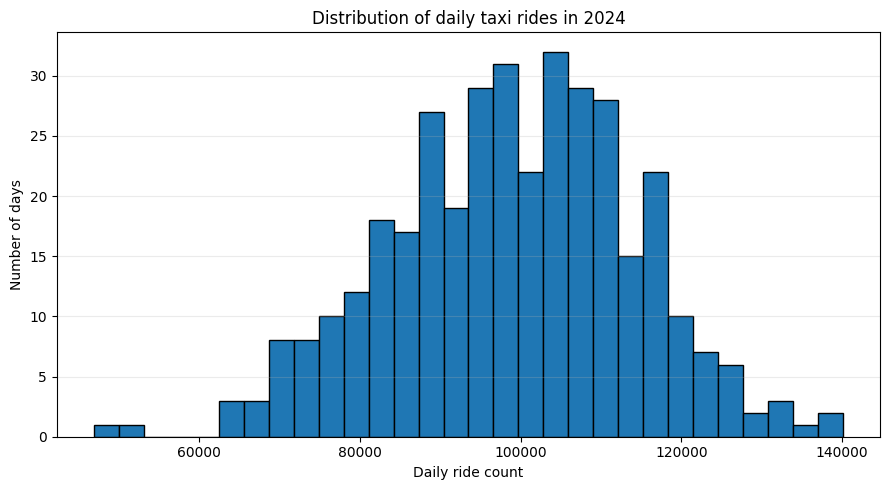

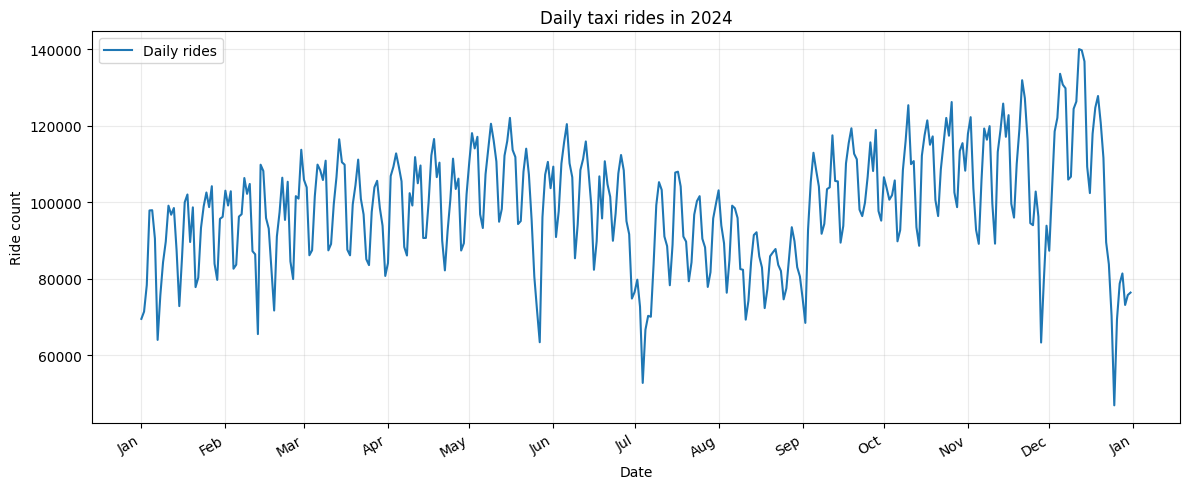

In [7]:
from IPython.display import display
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

print("Dataset shape:", dataset.shape)
display(dataset.head())
display(dataset.describe())
print("Schema:", dataset.schema)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(dataset["ride_count"].to_numpy(), bins=30, edgecolor="black")
ax.set_title("Distribution of daily taxi rides in 2024")
ax.set_xlabel("Daily ride count")
ax.set_ylabel("Number of days")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

rides_by_date = dataset.sort("date")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    rides_by_date["date"].to_list(),
    rides_by_date["ride_count"].to_list(),
    label="Daily rides",
)
ax.set_title("Daily taxi rides in 2024")
ax.set_xlabel("Date")
ax.set_ylabel("Ride count")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.25)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()